# Dependencies

In [1]:
# install torchaudio
!pip install torchaudio==0.7.0 -f https://download.pytorch.org/whl/torch_stable.html

Looking in links: https://download.pytorch.org/whl/torch_stable.html
     |████████████████████████████████| 7.6MB 7.9MB/s 
     |████████████████████████████████| 577.3MB 30kB/s 
ERROR: torchvision 0.9.1+cu101 has requirement torch==1.8.1, but you'll have torch 1.7.0+cu92 which is incompatible.
ERROR: torchtext 0.9.1 has requirement torch==1.8.1, but you'll have torch 1.7.0+cu92 which is incompatible.
  Found existing installation: torch 1.8.1+cu101
    Uninstalling torch-1.8.1+cu101:
      Successfully uninstalled torch-1.8.1+cu101


In [2]:
import os
import numpy as np
import pandas as pd

In [3]:
# current torch version is 1.7.0+cu101
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import warnings
warnings.filterwarnings("ignore")
import torchaudio

import matplotlib.pyplot as plt
import IPython.display as ipd

In [4]:
# check if cuda GPU is available, make sure you're using GPU runtime on Google Colab
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device) # you should output "cuda"

cuda


# Dataset

In [5]:
!gdown --id 1im5shxcavdoTRNT66mhVdtA_E0ZR8QLl
!unzip s1_train_release.zip

Downloading...
From: https://drive.google.com/uc?id=1im5shxcavdoTRNT66mhVdtA_E0ZR8QLl
To: /content/s1_train_release.zip
48.3MB [00:00, 72.8MB/s]
Archive:  s1_train_release.zip
   creating: s1_train_release/bird/
  inflating: s1_train_release/bird/train_bird_8400.wav  
  inflating: s1_train_release/bird/train_bird_8401.wav  
  inflating: s1_train_release/bird/train_bird_8402.wav  
  inflating: s1_train_release/bird/train_bird_8405.wav  
  inflating: s1_train_release/bird/train_bird_8406.wav  
  inflating: s1_train_release/bird/train_bird_8407.wav  
  inflating: s1_train_release/bird/train_bird_8408.wav  
  inflating: s1_train_release/bird/train_bird_8409.wav  
  inflating: s1_train_release/bird/train_bird_8411.wav  
  inflating: s1_train_release/bird/train_bird_8416.wav  
  inflating: s1_train_release/bird/train_bird_8417.wav  
  inflating: s1_train_release/bird/train_bird_8419.wav  
  inflating: s1_train_release/bird/train_bird_8420.wav  
  inflating: s1_train_release/bird/train_bird_8

In [6]:
class CustomSpeechDataset(torch.utils.data.Dataset):
  def __init__(self, path, typ='train', transforms=None):

    assert typ == 'train' or typ == 'test', 'typ must be either "train" or "test"'

    self.typ = typ
    self.transforms = transforms
    self.targets = []

    if self.typ == 'train':
      self.class_names = sorted(os.listdir(path))
      num_classes = len(self.class_names)

      for class_idx, class_name in enumerate(self.class_names):
        class_dirx = os.path.join(path, class_name)
        wav_list = os.listdir(class_dirx)

        for wav_file in wav_list:
          self.targets.append({
              'filename': wav_file,
              'path': os.path.join(class_dirx, wav_file),
              'class': class_name
          })

    if self.typ == 'test':
      wav_list = os.listdir(path)
      for wav_file in wav_list:
        self.targets.append({
            'filename': wav_file,
            'path': os.path.join(path, wav_file)
        })
  
  def __len__(self):
    return len(self.targets)

  def __getitem__(self, idx):
    if torch.is_tensor(idx):
      idx.tolist()

    signal, sr = torchaudio.load(self.targets[idx]['path'], normalization=True)
    filename = self.targets[idx]['filename']

    if self.transforms:
      for transform in self.transforms:
        signal = transform(signal)

    if self.typ == 'train':
      clx_name = self.targets[idx]['class']
      return filename, signal, sr, clx_name
    
    elif self.typ == 'test':
      return filename, signal, sr

In [7]:
full_dataset = CustomSpeechDataset(path='s1_train_release', typ='train')
train_size = int(len(full_dataset)*0.8)
valid_size = len(full_dataset) - train_size
train_set, valid_set = torch.utils.data.random_split(full_dataset, [train_size, valid_size])

In [8]:
labels = full_dataset.class_names

In [9]:
labels_to_indices = {}
for idx, l in enumerate(labels):
  labels_to_indices[l] = idx

Let's next look at one example from the training set.

In [10]:
filename, waveform, sample_rate, label_id = train_set[0]

Shape of waveform: torch.Size([1, 16000])
Sample rate of waveform: 16000


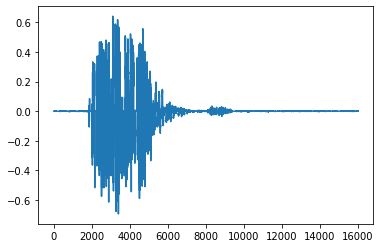

In [11]:
print("Shape of waveform: {}".format(waveform.size()))
print("Sample rate of waveform: {}".format(sample_rate))

# Let's plot the waveform using matplotlib
# We observe that the main audio activity happens at the later end of the clip
plt.plot(waveform.t().numpy());

In [12]:
# let's play the audio clip and hear it for ourselves!
ipd.Audio(waveform.numpy(), rate=sample_rate)

# Constant Sample Length

In [13]:
audio_lens = []
for i in range(len(train_set)):
  audio_lens.append(train_set[i][1].size(1))

print('Max Sample Length:', max(audio_lens))
print('Min Sample Length:', min(audio_lens))

Max Sample Length: 16000
Min Sample Length: 16000


In [14]:
class PadAudio(torch.nn.Module):
  def __init__(self, req_length = 16000):
    super().__init__()
    self.req_length = req_length

  def forward(self, waveform):
    while waveform.size(1) < self.req_length:
      waveform = torch.cat((waveform, waveform[:, :self.req_length - waveform.size(1)]), axis=1)
    return waveform

# let's set up a list of transformations we are going to apply to the waveforms
transformations = []
transformations.append(PadAudio())

# Features

In [15]:
from torchaudio.transforms import MelSpectrogram

# We define our own log transformation here
class LogMelTransform(torch.nn.Module):

    def __init__(self, log_offset = 1e-6):
        super().__init__()
        self.log_offset = log_offset

    def forward(self, melspectrogram):
        return torch.log(melspectrogram + self.log_offset)

# Let's append these new transformations
transformations.append(MelSpectrogram(sample_rate = 16000, n_mels = 128))
transformations.append(LogMelTransform())

## Data Augmentation

In [16]:
from torchaudio.transforms import TimeMasking, FrequencyMasking

eval_transformations = transformations.copy()

# Let's extend the list of transformations with the augmentations
transformations.append(TimeMasking(time_mask_param = 10)) # a maximum of 10 time steps will be masked
transformations.append(FrequencyMasking(freq_mask_param = 3)) # maximum of 3 freq channels will be masked

# Data Loader

In [17]:
BATCH_SIZE = 32
NUM_WORKERS = 4
PIN_MEMORY = True if device == 'cuda' else False

def train_collate_fn(batch):

    # A data tuple has the form:
    # filename, waveform, sample_rate, label

    tensors, targets, filenames = [], [], []

    # Gather in lists, and encode labels as indices
    for filename, waveform, sample_rate, label in batch:
        # apply transformations
        for transform in transformations:
            waveform = transform(waveform)
        waveform = waveform.squeeze().T
        tensors += [waveform]
        targets += [labels_to_indices[label]]
        filenames += [filename]

    # Group the list of tensors into a batched tensor
    tensors = torch.stack(tensors)
    targets = torch.LongTensor(targets)

    return (tensors, targets, filenames)

def eval_collate_fn(batch):

    # A data tuple has the form:
    # filename, waveform, sample_rate, label

    tensors, targets, filenames = [], [], []

    # Gather in lists, and encode labels as indices
    for filename, waveform, sample_rate, label in batch:
        # apply transformations
        for transform in eval_transformations:
            waveform = transform(waveform)
        waveform = waveform.squeeze().T
        tensors += [waveform]
        targets += [labels_to_indices[label]]
        filenames += [filename]

    # Group the list of tensors into a batched tensor
    tensors = torch.stack(tensors)
    targets = torch.LongTensor(targets)
    filenames += [filename]

    return (tensors, targets, filenames)

train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    collate_fn=train_collate_fn,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

valid_loader = torch.utils.data.DataLoader(
    valid_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    collate_fn=eval_collate_fn,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

# Model Setup

In [18]:
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, device, classes=None):
        super(RNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)
        self.device = device
        self.classes = classes

    def forward(self, x):
        # Set initial hidden and cell states
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, batch_size, self.hidden_size).to(self.device) 
        c0 = torch.zeros(self.num_layers, batch_size, self.hidden_size).to(self.device) 
        
        # Forward propagate LSTM
        out, _ = self.lstm(x, (h0, c0))  # shape = (batch_size, seq_length, hidden_size)
        
        # Decode the hidden state of the last time step
        out = self.fc(out[:, -1, :])
        return out

    def predict(self, x):
        '''Predict one label from one sample's features'''
        # x: feature from a sample, LxN
        #   L is length of sequency
        #   N is feature dimension
        x = torch.tensor(x[np.newaxis, :], dtype=torch.float32)
        x = x.to(self.device)
        outputs = self.forward(x)
        _, predicted = torch.max(outputs.data, 1)
        predicted_index = predicted.item()
        return predicted_index

In [19]:
# initialize the model class
model = RNN(input_size=128, hidden_size=128, num_layers=2, num_classes=len(labels), device=device, classes=labels).to(device)

In [20]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
optimizer.zero_grad()
num_epochs = 50

In [21]:
for epoch in range(1,num_epochs+1):

  # training steps
  model.train()
  count_correct, count_total = 0, 0
  for idx, (features, targets, filenames) in enumerate(train_loader):

    features = features.to(device)
    targets = targets.to(device)

    # forward pass
    outputs = model(features)
    loss = criterion(outputs, targets)

    # backward pass
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    # training results
    _, argmax = torch.max(outputs, 1)
    count_correct += (targets == argmax.squeeze()).sum().item()
    count_total += targets.size(0)

  train_acc = count_correct / count_total
  
  # evaluation steps
  model.eval()
  count_correct, count_total = 0, 0
  with torch.no_grad():
    for idx, (features, targets, filenames) in enumerate(valid_loader):

      features = features.to(device)
      targets = targets.to(device)

      # forward pass
      val_outputs = model(features)
      val_loss = criterion(val_outputs, targets)

      # validation results
      _, argmax = torch.max(val_outputs, 1)
      count_correct += (targets == argmax.squeeze()).sum().item()
      count_total += targets.size(0)

  # print results
  valid_acc = count_correct / count_total
  print('Epoch [{}/{}], Train loss = {:.4f}, Train accuracy = {:.2f}, Valid loss = {:.4f}, Valid accuracy = {:.2f}' 
        .format(epoch, num_epochs, loss.item(), 100*train_acc, val_loss.item(), 100*valid_acc))


Epoch [1/50], Train loss = 2.5353, Train accuracy = 11.68, Valid loss = 2.5210, Valid accuracy = 12.31
Epoch [2/50], Train loss = 2.3443, Train accuracy = 17.31, Valid loss = 2.4234, Valid accuracy = 17.50
Epoch [3/50], Train loss = 2.1733, Train accuracy = 20.87, Valid loss = 2.1593, Valid accuracy = 23.08
Epoch [4/50], Train loss = 2.0011, Train accuracy = 26.59, Valid loss = 2.0666, Valid accuracy = 25.19
Epoch [5/50], Train loss = 2.0665, Train accuracy = 29.81, Valid loss = 1.7930, Valid accuracy = 26.92
Epoch [6/50], Train loss = 1.7945, Train accuracy = 34.18, Valid loss = 1.7496, Valid accuracy = 36.15
Epoch [7/50], Train loss = 1.6787, Train accuracy = 38.89, Valid loss = 1.5511, Valid accuracy = 40.96
Epoch [8/50], Train loss = 1.5554, Train accuracy = 41.44, Valid loss = 1.6663, Valid accuracy = 43.46
Epoch [9/50], Train loss = 1.8829, Train accuracy = 45.53, Valid loss = 1.4033, Valid accuracy = 43.46
Epoch [10/50], Train loss = 1.7047, Train accuracy = 47.69, Valid loss = 

In [22]:
torch.save(model.state_dict(), 'speech_classification_lstm.pt')

# Test Set

In [23]:
!gdown --id 1AvP49xengGjnFTG209AgvAGj-by8WGSi
!unzip -q -o s1_test.zip

Downloading...
From: https://drive.google.com/uc?id=1AvP49xengGjnFTG209AgvAGj-by8WGSi
To: /content/s1_test.zip
12.3MB [00:00, 46.4MB/s]


In [24]:
# Initialise dataset object for test set
test_set = CustomSpeechDataset(path='s1_test', typ='test')

In [25]:
# define test collate function and set up test loader

def test_collate_fn(batch):

    # A data tuple has the form:
    # filename, waveform, sample_rate

    tensors, filenames = [], []

    # Gather in lists
    for filename, waveform, sample_rate in batch:
        # apply transformations
        for transform in eval_transformations:
            waveform = transform(waveform)
        waveform = waveform.squeeze().T
        tensors += [waveform]
        filenames += [filename]

    # Group the list of tensors into a batched tensor
    tensors = torch.stack(tensors)

    return (tensors, filenames)

test_loader = torch.utils.data.DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    collate_fn=test_collate_fn,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

In [26]:
# pass test set through the RNN model
model.eval()
pred_list, filename_list = [], []
with torch.no_grad():
  for idx, (features, filenames) in enumerate(test_loader):

    features = features.to(device)

    # forward pass
    outputs = model(features)

    # validation results
    _, argmax = torch.max(outputs, 1)
    pred_list += argmax.cpu().tolist()
    filename_list += filenames

# Submission

Submission csv file should contain only 2 columns for filename and label, in that order. The file should be sorted by filename, and exclude headers.

Refer to sample_submission.csv for an example.

In [27]:
result_tuple = list(zip(filename_list, pred_list))
submission = pd.DataFrame(result_tuple, columns=['filename', 'pred'])
submission = submission.sort_values('filename').reset_index(drop=True)
submission['label'] = submission['pred'].apply(lambda x: labels[x])

In [28]:
submission[['filename', 'label']].head()
submission[['filename', 'label']].to_csv('submission.csv', header=None, index=None)